In [1]:
import pandas as pd

df = pd.read_csv("../data/kerala_water_quality_cleaned.csv")

In [2]:
df.shape

(1155, 21)

In [3]:
df.columns


Index(['_id', 'SlNo', 'Station', 'Agency', 'State LGD Code', 'State',
       'District LGD Code', 'District', 'Tehsil', 'River', 'Basin',
       'Tributary', 'Subtributary', 'SubSubtributary', 'Local River',
       'Latitude', 'Longitude', 'Data Acquisition Time',
       'Biochemical Oxygen Demand (mg/L)', 'Fecal Coliform (MPN/100mL)',
       'Total Coliform (MPN/100mL)'],
      dtype='str')

In [4]:
df["Station"].nunique()


129

In [8]:
df[[
    "Biochemical Oxygen Demand (mg/L)",
    "Fecal Coliform (MPN/100mL)",
    "Total Coliform (MPN/100mL)"
]].describe()

,Biochemical Oxygen Demand (mg/L),Fecal Coliform (MPN/100mL),Total Coliform (MPN/100mL)
count,1155.000000,1155.000000,1155.000000
mean,2.076797,660.211255,1328.386147
std,0.967988,2833.529324,7050.053488
min,1.100000,4.000000,12.000000
25%,1.800000,100.000000,620.000000
50%,1.900000,130.000000,620.000000
75%,2.000000,310.000000,620.000000
max,8.200000,70000.000000,200000.000000


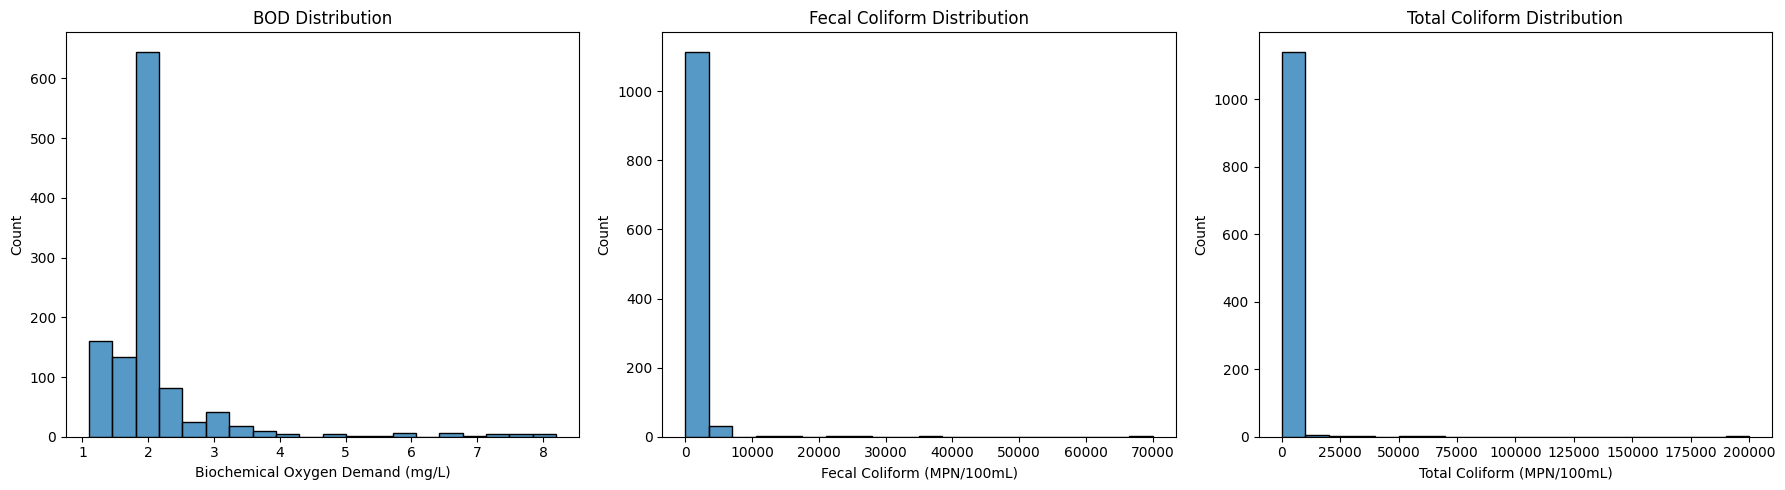

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(df["Biochemical Oxygen Demand (mg/L)"], bins=20, ax=axes[0])
axes[0].set_title("BOD Distribution")

sns.histplot(df["Fecal Coliform (MPN/100mL)"], bins=20, ax=axes[1])
axes[1].set_title("Fecal Coliform Distribution")

sns.histplot(df["Total Coliform (MPN/100mL)"], bins=20, ax=axes[2])
axes[2].set_title("Total Coliform Distribution")

plt.tight_layout()
plt.show()

In [10]:
district_bod = df.groupby("District")[
    "Biochemical Oxygen Demand (mg/L)"
].mean().sort_values(ascending=False)

district_bod

District
THIRUVANANTHAPURAM    3.403571
Alappuzha             2.128713
Kollam                2.095588
ERNAKULAM             2.094059
KOTTAYAM              2.000000
PATHANAMTHITTA        1.963636
PALAKKAD              1.901176
IDUKKI                1.858621
KOZHIKODE             1.853922
MALAPPURAM            1.825000
THRISSUR              1.816456
KANNUR                1.787273
KASARAGOD             1.785897
WAYANAD               1.672973
Name: Biochemical Oxygen Demand (mg/L), dtype: float64

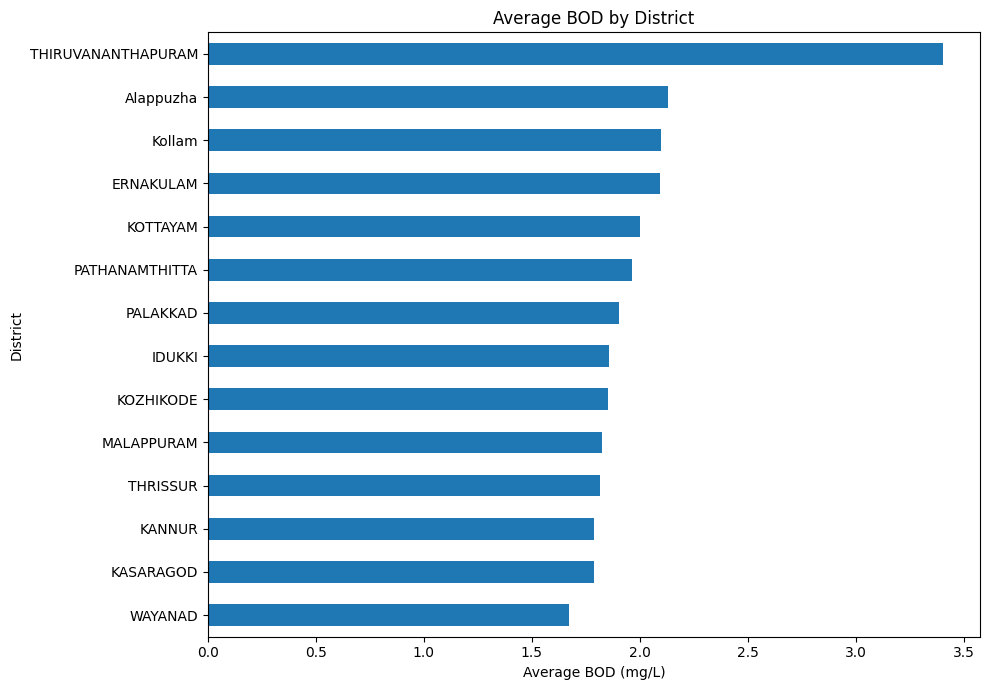

In [11]:
import matplotlib.pyplot as plt

district_bod.sort_values().plot(kind="barh", figsize=(10, 7))

plt.title("Average BOD by District")
plt.xlabel("Average BOD (mg/L)")
plt.ylabel("District")
plt.tight_layout()
plt.show()

In [12]:
district_fecal = df.groupby("District")[
    "Fecal Coliform (MPN/100mL)"
].mean().sort_values(ascending=False)

district_fecal

District
KOZHIKODE             3385.372549
IDUKKI                1057.586207
ERNAKULAM              868.628713
THIRUVANANTHAPURAM     648.035714
KOTTAYAM               497.307692
MALAPPURAM             487.533333
THRISSUR               327.101266
PATHANAMTHITTA         234.772727
PALAKKAD               215.541176
Alappuzha              122.940594
Kollam                 112.823529
KASARAGOD               85.294872
KANNUR                  69.309091
WAYANAD                 62.648649
Name: Fecal Coliform (MPN/100mL), dtype: float64